In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

BASE = "/content/drive/MyDrive/recensioni-bayes"
for cartella in ["data/raw", "data/processed"]:
    os.makedirs(f"{BASE}/{cartella}", exist_ok=True)

print(os.listdir(BASE))

['data', 'figures']


In [3]:
import pandas, numpy, scipy, matplotlib, pyarrow
print("tutto ok", pandas.__version__)

tutto ok 2.2.3


In [4]:
URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"
FILE_RAW = f"{BASE}/data/raw/All_Beauty.jsonl.gz"

!wget -q --show-progress -O "{FILE_RAW}" "{URL}"
!ls -lh "{BASE}/data/raw"

/content/drive/MyDr 100%[===================>]  90.07M  21.8MB/s    in 4.4s    
total 91M
-rw------- 1 root root 91M Jan 16  2025 All_Beauty.jsonl.gz


In [5]:
import pandas as pd

COLONNE = ["parent_asin", "user_id", "rating", "timestamp", "verified_purchase", "text"]

pezzi = []
for pezzo in pd.read_json(FILE_RAW, lines=True, compression="gzip", chunksize=100_000):
    pezzi.append(pezzo[COLONNE])

df = pd.concat(pezzi, ignore_index=True)
print(df.shape)

(701528, 6)


In [6]:
df["data"] = pd.to_datetime(df["timestamp"], unit="ms")

FILE_PARQUET = f"{BASE}/data/processed/recensioni.parquet"
df.to_parquet(FILE_PARQUET)

print(df["data"].min(), "→", df["data"].max())
df.head()

2000-11-01 04:24:18 → 2023-09-09 00:39:36.666000


,parent_asin,user_id,rating,timestamp,verified_purchase,text,data
0,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,5,2020-05-05 14:08:48.923,True,This spray is really nice. It smells really go...,2020-05-05 14:08:48.923
1,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,4,2020-05-04 18:10:55.070,True,"This product does what I need it to do, I just...",2020-05-04 18:10:55.070
2,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,5,2020-05-16 21:41:06.052,True,"Smells good, feels great!",2020-05-16 21:41:06.052
3,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1,2022-01-28 18:13:50.220,True,Felt synthetic,2022-01-28 18:13:50.220
4,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,5,2020-12-30 10:02:43.534,True,Love it,2020-12-30 10:02:43.534


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/recensioni-bayes"
FILE_PARQUET = f"{BASE}/data/processed/recensioni.parquet"

df = pd.read_parquet(FILE_PARQUET)
df = df.drop(columns="timestamp")

print("recensioni:", len(df))
print("prodotti:  ", df["parent_asin"].nunique())
print("utenti:    ", df["user_id"].nunique())

recensioni: 701528
prodotti:   112565
utenti:     631986


rating
1    102080
2     43034
3     56307
4     79381
5    420726
Name: count, dtype: int64


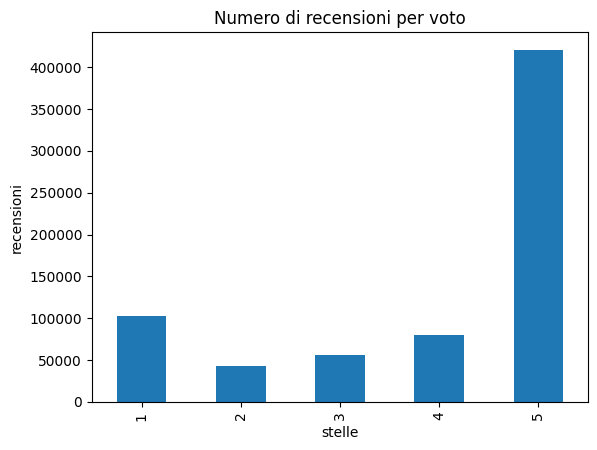

quota di recensioni positive: 0.713


In [8]:
voti = df["rating"].value_counts().sort_index()
print(voti)

voti.plot(kind="bar")
plt.title("Numero di recensioni per voto")
plt.xlabel("stelle"); plt.ylabel("recensioni")
plt.show()

df["positiva"] = (df["rating"] >= 4).astype(int)
print("quota di recensioni positive:", round(df["positiva"].mean(), 3))

In [9]:
prodotti = df.groupby("parent_asin").agg(
    n=("positiva", "size"),
    k=("positiva", "sum"),
)

print(prodotti["n"].describe())
print("prodotti con 1 sola recensione:", round((prodotti["n"] == 1).mean(), 3))
print("prodotti con 5 o meno:         ", round((prodotti["n"] <= 5).mean(), 3))

count    112565.000000
mean          6.232204
std          25.189840
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1962.000000
Name: n, dtype: float64
prodotti con 1 sola recensione: 0.423
prodotti con 5 o meno:          0.797


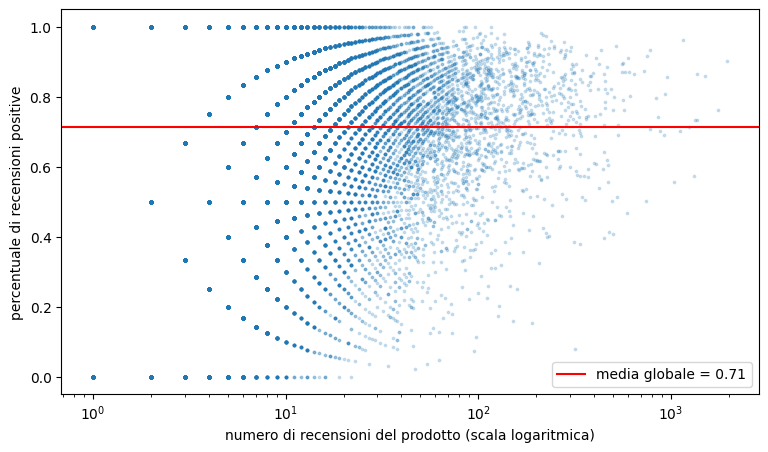

,n,k,perc
parent_asin,,,
B0CFZKJ4KY,2,2,1.0
0005946468,1,1,1.0
0123034892,1,1,1.0
B0CBJS48PB,1,1,1.0
B0C8RY9PJH,3,3,1.0
B0C8NMSN3M,1,1,1.0
1908505753,1,1,1.0
1891129716,2,2,1.0
1741666929,1,1,1.0


In [10]:
prodotti["perc"] = prodotti["k"] / prodotti["n"]
media = df["positiva"].mean()

plt.figure(figsize=(9, 5))
plt.scatter(prodotti["n"], prodotti["perc"], s=3, alpha=0.2)
plt.axhline(media, color="red", label=f"media globale = {media:.2f}")
plt.xscale("log")
plt.xlabel("numero di recensioni del prodotto (scala logaritmica)")
plt.ylabel("percentuale di recensioni positive")
plt.legend()
plt.show()

prodotti.sort_values("perc", ascending=False).head(10)

In [11]:
prima = len(df)

# stessa persona, stesso prodotto, stesso testo: è la stessa recensione ripetuta
df = df.drop_duplicates(subset=["parent_asin", "user_id", "text"])
print("copie identiche rimosse:", prima - len(df))

# stessa persona che recensisce lo stesso prodotto più volte: teniamo solo la prima
df = df.sort_values("data")
doppie = df.duplicated(subset=["parent_asin", "user_id"]).sum()
df = df.drop_duplicates(subset=["parent_asin", "user_id"], keep="first")
print("recensioni ripetute dalla stessa persona rimosse:", doppie)
print("recensioni rimaste:", len(df))

copie identiche rimosse: 7300
recensioni ripetute dalla stessa persona rimosse: 299
recensioni rimaste: 693929


In [12]:
print(df["verified_purchase"].value_counts(normalize=True).round(3))
print(df.groupby("verified_purchase")["positiva"].mean().round(3))

verified_purchase
True     0.905
False    0.095
Name: proportion, dtype: float64
verified_purchase
False    0.757
True     0.708
Name: positiva, dtype: float64


data
2000         1
2001        11
2002        24
2003        56
2004       130
2005       265
2006       416
2007      1150
2008      1251
2009      1198
2010      1568
2011      1855
2012      2774
2013      7875
2014     16095
2015     35838
2016     62044
2017     67361
2018     71984
2019     98107
2020    125384
2021    123458
2022     60887
2023     14197
dtype: int64


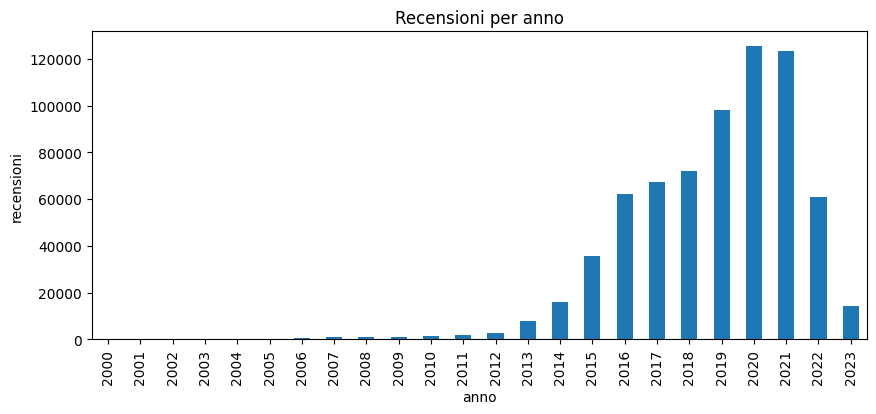

In [13]:
per_anno = df.groupby(df["data"].dt.year).size()
print(per_anno)

per_anno.plot(kind="bar", figsize=(10, 4))
plt.title("Recensioni per anno")
plt.xlabel("anno"); plt.ylabel("recensioni")
plt.show()

In [14]:
TAGLIO = pd.Timestamp("2021-01-01")

passato = df[df["data"] < TAGLIO]
futuro  = df[df["data"] >= TAGLIO]

train = passato.groupby("parent_asin").agg(n=("positiva", "size"), k=("positiva", "sum"))
test  = futuro.groupby("parent_asin").agg(n_fut=("positiva", "size"), k_fut=("positiva", "sum"))

tab = train.join(test, how="inner")

print("recensioni passato / futuro:", len(passato), "/", len(futuro))
print("prodotti nel passato:", len(train))
print("prodotti nel futuro: ", len(test))
print("prodotti in entrambi:", len(tab))

recensioni passato / futuro: 495387 / 198542
prodotti nel passato: 80187
prodotti nel futuro:  49351
prodotti in entrambi: 16973


In [15]:
print(tab["n"].describe())
print("prodotti con 5 o meno recensioni nel passato:", round((tab["n"] <= 5).mean(), 3))
print("quota positive passato:", round(passato["positiva"].mean(), 3))
print("quota positive futuro: ", round(futuro["positiva"].mean(), 3))

tab.to_parquet(f"{BASE}/data/processed/tabella_modello.parquet")
tab.head()

count    16973.000000
mean        13.069935
std         44.779909
min          1.000000
25%          1.000000
50%          3.000000
75%          9.000000
max       1713.000000
Name: n, dtype: float64
prodotti con 5 o meno recensioni nel passato: 0.623
quota positive passato: 0.734
quota positive futuro:  0.66


,n,k,n_fut,k_fut
parent_asin,,,,
069267599X,35,33,6,5
0990995119,6,6,1,1
1453085815,8,3,1,0
1891129716,1,1,1,1
1931292108,1,1,1,1


In [16]:
df = df[df["verified_purchase"]]
df.to_parquet(f"{BASE}/data/processed/recensioni_pulite.parquet")

passato = df[df["data"] < TAGLIO]
futuro  = df[df["data"] >= TAGLIO]

train = passato.groupby("parent_asin").agg(n=("positiva", "size"), k=("positiva", "sum"))
test  = futuro.groupby("parent_asin").agg(n_fut=("positiva", "size"), k_fut=("positiva", "sum"))
tab = train.join(test, how="inner")

print("recensioni passato / futuro:", len(passato), "/", len(futuro))
print("prodotti in entrambi:", len(tab))
print("mediana recensioni passate:", tab["n"].median())
print("prodotti con 5 o meno:", round((tab["n"] <= 5).mean(), 3))
print("quota positive passato / futuro:", round(passato["positiva"].mean(), 3), "/", round(futuro["positiva"].mean(), 3))

tab.to_parquet(f"{BASE}/data/processed/tabella_modello.parquet")

recensioni passato / futuro: 448405 / 179784
prodotti in entrambi: 16024
mediana recensioni passate: 3.0
prodotti con 5 o meno: 0.63
quota positive passato / futuro: 0.73 / 0.654


In [17]:
from scipy.special import betaln
from scipy.optimize import minimize

k = train["k"].values
n = train["n"].values

def errore(params):
    a, b = np.exp(params)
    return -np.mean(betaln(k + a, n - k + b) - betaln(a, b))

risultato = minimize(errore, x0=[0.0, 0.0], method="L-BFGS-B")
alpha, beta = np.exp(risultato.x)

print("alpha =", round(alpha, 3))
print("beta  =", round(beta, 3))
print("mu    =", round(alpha / (alpha + beta), 3))
print("m     =", round(alpha + beta, 3))

alpha = 4.496
beta  = 1.767
mu    = 0.718
m     = 6.263


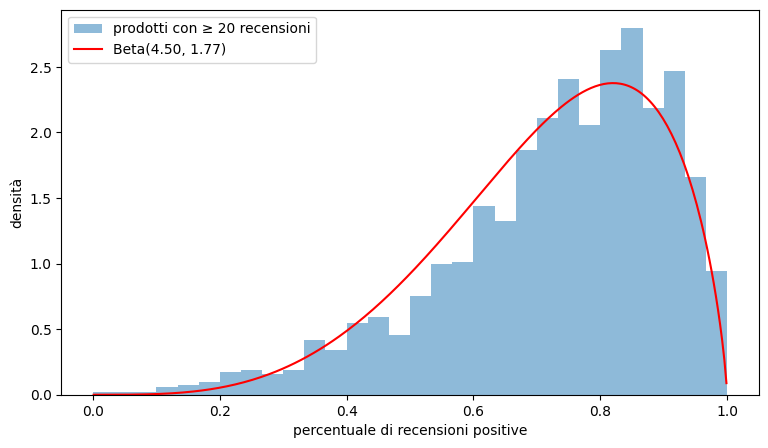

prodotti con almeno 20 recensioni: 3885


In [18]:
from scipy.stats import beta as distr_beta

affidabili = train[train["n"] >= 20]
perc = affidabili["k"] / affidabili["n"]

x = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(9, 5))
plt.hist(perc, bins=30, density=True, alpha=0.5, label="prodotti con ≥ 20 recensioni")
plt.plot(x, distr_beta.pdf(x, alpha, beta), "r", label=f"Beta({alpha:.2f}, {beta:.2f})")
plt.xlabel("percentuale di recensioni positive"); plt.ylabel("densità")
plt.legend(); plt.show()

print("prodotti con almeno 20 recensioni:", len(affidabili))

In [19]:
media_passato = passato["positiva"].mean()
eps = 0.001

prev = pd.DataFrame(index=tab.index)
prev["grezza"]        = (tab["k"] / tab["n"]).clip(eps, 1 - eps)
prev["media globale"] = media_passato
prev["laplace"]       = (tab["k"] + 1) / (tab["n"] + 2)
prev["bayes"]         = (tab["k"] + alpha) / (tab["n"] + alpha + beta)

prev.head()

,grezza,media globale,laplace,bayes
parent_asin,,,,
069267599X,0.970588,0.73007,0.944444,0.931282
0990995119,0.999000,0.73007,0.875000,0.855925
1453085815,0.285714,0.73007,0.333333,0.489801
1891129716,0.999000,0.73007,0.666667,0.756742
2464782475,0.500000,0.73007,0.500000,0.665160


In [20]:
kf = tab["k_fut"]
nf = tab["n_fut"]

def log_loss(p):
    return -(kf * np.log(p) + (nf - kf) * np.log(1 - p)).sum() / nf.sum()

def brier(p):
    return (kf * (1 - p) ** 2 + (nf - kf) * p ** 2).sum() / nf.sum()

risultati = pd.DataFrame({
    metodo: {"log-loss": log_loss(prev[metodo]), "brier": brier(prev[metodo])}
    for metodo in prev.columns
}).T

risultati.round(4).sort_values("log-loss")

,log-loss,brier
bayes,0.5958,0.2025
laplace,0.6043,0.2057
media globale,0.6208,0.2144
grezza,1.0398,0.2337


In [21]:
fasce = pd.cut(tab["n"], bins=[0, 1, 5, 20, np.inf], labels=["1", "2-5", "6-20", ">20"])

righe = {}
for fascia in fasce.cat.categories:
    sel = fasce == fascia
    righe[fascia] = {
        metodo: -(kf[sel] * np.log(prev.loc[sel, metodo])
                  + (nf[sel] - kf[sel]) * np.log(1 - prev.loc[sel, metodo])).sum() / nf[sel].sum()
        for metodo in prev.columns
    }
    righe[fascia]["prodotti"] = sel.sum()

pd.DataFrame(righe).T.round(4)

,grezza,media globale,laplace,bayes,prodotti
1,2.6063,0.6343,0.6669,0.6289,4245.0
2-5,1.3539,0.6277,0.6275,0.6136,5844.0
6-20,0.8360,0.6276,0.6144,0.6102,3981.0
>20,0.5785,0.6091,0.5687,0.5683,1954.0


In [22]:
FIG = f"{BASE}/figures"
os.makedirs(FIG, exist_ok=True)

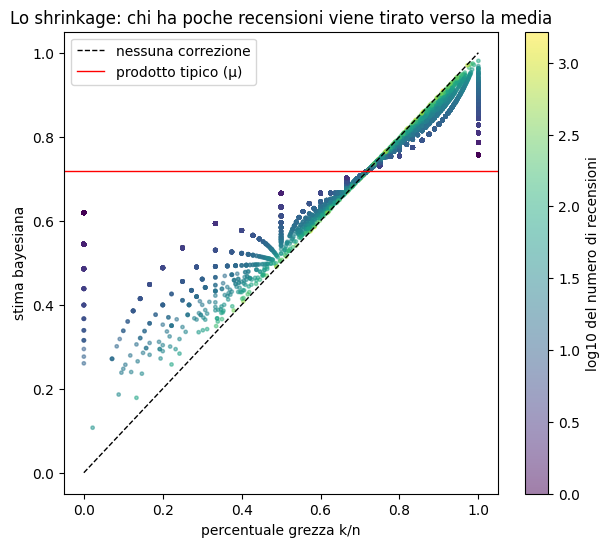

In [23]:
grezza_vera = tab["k"] / tab["n"]

plt.figure(figsize=(7, 6))
sc = plt.scatter(grezza_vera, prev["bayes"], c=np.log10(tab["n"]), s=6, alpha=0.5, cmap="viridis")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="nessuna correzione")
plt.axhline(alpha / (alpha + beta), color="red", lw=1, label="prodotto tipico (μ)")
plt.colorbar(sc, label="log10 del numero di recensioni")
plt.xlabel("percentuale grezza k/n"); plt.ylabel("stima bayesiana")
plt.title("Lo shrinkage: chi ha poche recensioni viene tirato verso la media")
plt.legend(); plt.savefig(f"{FIG}/shrinkage.png", dpi=150, bbox_inches="tight"); plt.show()

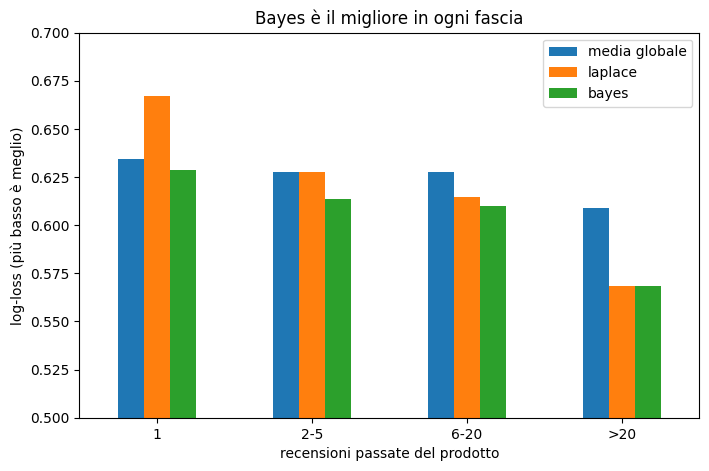

In [24]:
per_fascia = pd.DataFrame(righe).T.drop(columns=["prodotti", "grezza"])

per_fascia.plot(kind="bar", figsize=(8, 5))
plt.xlabel("recensioni passate del prodotto"); plt.ylabel("log-loss (più basso è meglio)")
plt.ylim(0.5, 0.7)
plt.title("Bayes è il migliore in ogni fascia")
plt.xticks(rotation=0)
plt.savefig(f"{FIG}/errore_per_fascia.png", dpi=150, bbox_inches="tight"); plt.show()

In [25]:
classifica = train.copy()
classifica["grezza"] = classifica["k"] / classifica["n"]
classifica["bayes"]  = (classifica["k"] + alpha) / (classifica["n"] + alpha + beta)

print("TOP 10 per percentuale grezza")
display(classifica.sort_values(["grezza", "n"], ascending=False).head(10).round(3))

print("TOP 10 per stima bayesiana")
display(classifica.sort_values("bayes", ascending=False).head(10).round(3))

TOP 10 per percentuale grezza


,n,k,grezza,bayes
parent_asin,,,,
B07M6MXTH2,85,85,1.0,0.981
B07DT5FHY4,82,82,1.0,0.980
B01448SZ0U,80,80,1.0,0.980
B00H3WGN9K,74,74,1.0,0.978
B002T5NMGS,49,49,1.0,0.968
B07T9Z9P82,49,49,1.0,0.968
B0006PJTKG,48,48,1.0,0.967
B07DL991L4,43,43,1.0,0.964
B000FQMMWI,42,42,1.0,0.963


TOP 10 per stima bayesiana


,n,k,grezza,bayes
parent_asin,,,,
B07M6MXTH2,85,85,1.000,0.981
B07DT5FHY4,82,82,1.000,0.980
B01448SZ0U,80,80,1.000,0.980
B00H3WGN9K,74,74,1.000,0.978
B07P6TN5RF,140,138,0.986,0.974
B01N47XMWS,206,202,0.981,0.973
B01I5MFUZ4,89,88,0.989,0.971
B0C9CWKY9G,726,706,0.972,0.970
B06XHPHHR4,112,110,0.982,0.968


In [26]:
print("alpha =", round(alpha, 3), " beta =", round(beta, 3))

classifica["posizione_grezza"] = classifica["grezza"].rank(ascending=False, method="min").astype(int)
classifica["posizione_bayes"]  = classifica["bayes"].rank(ascending=False, method="min").astype(int)

perfetti = classifica["grezza"] == 1
print("prodotti al 100%:", perfetti.sum())
print("di cui con 3 recensioni o meno:", (perfetti & (classifica["n"] <= 3)).sum())

classifica.sort_values("bayes", ascending=False).head(10)[
    ["n", "k", "grezza", "bayes", "posizione_grezza", "posizione_bayes"]
].round(3)

alpha = 4.496  beta = 1.767
prodotti al 100%: 37873
di cui con 3 recensioni o meno: 33586


,n,k,grezza,bayes,posizione_grezza,posizione_bayes
parent_asin,,,,,,
B07M6MXTH2,85,85,1.000,0.981,1,1
B07DT5FHY4,82,82,1.000,0.980,1,2
B01448SZ0U,80,80,1.000,0.980,1,3
B00H3WGN9K,74,74,1.000,0.978,1,4
B07P6TN5RF,140,138,0.986,0.974,37875,5
B01N47XMWS,206,202,0.981,0.973,37880,6
B01I5MFUZ4,89,88,0.989,0.971,37874,7
B0C9CWKY9G,726,706,0.972,0.970,37907,8
B06XHPHHR4,112,110,0.982,0.968,37877,9
